### Probabilistic Analysis: Figgie Hand Distributions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from src.figgie_deck_generator import Hand, SUIT_CLASS, Suit, Figgie_Deck 
from src.figgie_deck_generator import DECK_CAP

#### Question 1: How does 1 Hand predict the Common/Goal Suit?
- We can further divide this into other questions:
    - What does the distribution of each suit look like, given one deck?
    - 


In [2]:
# Testing runtimes:

figgie_deck = Figgie_Deck()
figgie_deck.shuffle_deck(show_runtime=True)
all_hands = figgie_deck.deal_deck(num_players = 5, show_runtime = True)
figgie_deck.deck_reset()
figgie_deck.shuffle_deck(show_runtime=True)
indiv_hand = figgie_deck.distr_hand(hand_size = 8, show_runtime = True)

print("\n5 Deals:")
figgie_deck.deck_reset()
figgie_deck.shuffle_deck(show_runtime=True)
d_start_time = time.perf_counter()
for i in range(5):
    indiv_hand = figgie_deck.distr_hand(hand_size = 8, show_runtime = True)
d_elapsed_time = time.perf_counter() - d_start_time
print(f"Total 5-deal runtime: {d_elapsed_time*1000:.2f}ms")
print(figgie_deck)

Runtime: 1.15ms
Dealing Runtime: 0.39ms
Runtime: 0.19ms
Deal 1 Hand Runtime: 0.07ms

5 Deals:
Runtime: 0.16ms
Deal 1 Hand Runtime: 0.08ms
Deal 1 Hand Runtime: 0.05ms
Deal 1 Hand Runtime: 0.04ms
Deal 1 Hand Runtime: 0.05ms
Deal 1 Hand Runtime: 0.04ms
Total 5-deal runtime: 0.50ms
Spades
  Black
  SUIT_CLASS.GOAL, 0
Clubs
  Black
  SUIT_CLASS.COMMON, 0
Hearts
  Red
  SUIT_CLASS.NORMAL, 0
Diamonds
  Red
  SUIT_CLASS.NORMAL, 0



In [4]:
nsamples = int(1e5)
# Actually 5000 for 5 players
figgie_deck = Figgie_Deck()
figgie_deck.shuffle_deck()

sampling_start = time.perf_counter()
sample_hands_common: dict[str, list[Hand]] = {"Spades": [], 
                                       "Clubs": [],
                                       "Hearts": [],
                                       "Diamonds": []}
sample_hands_goal: dict[str, list[Hand]] = {"Spades": [], 
                                       "Clubs": [],
                                       "Hearts": [],
                                       "Diamonds": []}
for i in range(nsamples):
    all_hands = figgie_deck.deal_deck(num_players = 5, show_runtime=False)
    sample_hands_common[str(figgie_deck.get_common_suit())] += all_hands
    sample_hands_goal[str(figgie_deck.get_goal_suit())] += all_hands
    figgie_deck.deck_reset()
    figgie_deck.shuffle_deck(show_runtime=False)
sampling_end = time.perf_counter() - sampling_start
print(f"Sampling runtime: {sampling_end:.2f}s")

Runtime: 0.49ms
Sampling runtime: 9.40s


In [5]:
num_players = 5
max_ct = DECK_CAP // num_players

raw_common_suit_cts = []
raw_goal_suit_cts = []
ct_start = time.perf_counter()

raw_common_suit_cts = np.array([sample[suit] for suit, samples in sample_hands_common.items()
                                for sample in samples])
raw_goal_suit_cts = np.array([sample[suit] for suit, samples in sample_hands_goal.items()
                                for sample in samples])
common_counts = np.bincount(raw_common_suit_cts, minlength=max_ct + 1)
goal_counts = np.bincount(raw_goal_suit_cts, minlength=max_ct + 1)

ct_end = time.perf_counter() - ct_start
print(f"Common Suit Counting Runtime: {ct_end:.2f}s")
print(raw_common_suit_cts[:10])
print(raw_goal_suit_cts[:10])

Common Suit Counting Runtime: 0.18s
[4 2 3 2 1 0 3 4 3 2]
[2 2 3 0 1 1 2 3 1 1]


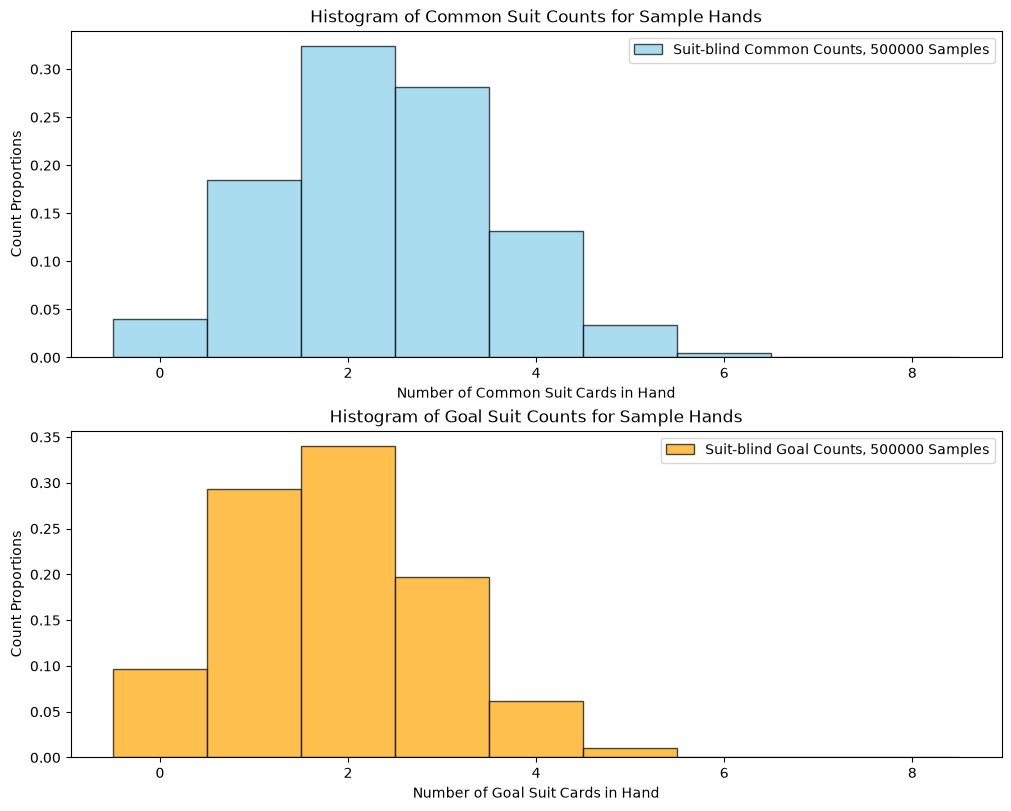

In [7]:
bins = np.arange(-0.5, max_ct + 1.5, 1)

fig, ax = plt.subplots(2, 1, figsize=(10, 8), layout="constrained")
ax[0].hist(raw_common_suit_cts, bins=bins, density=True,
        color="skyblue", edgecolor="black", alpha=0.7, label=f"Suit-blind Common Counts, {num_players*nsamples} Samples")
ax[0].set_title("Histogram of Common Suit Counts for Sample Hands")
ax[0].set_xlabel("Number of Common Suit Cards in Hand")
ax[0].set_ylabel("Count Proportions")
ax[0].legend()

ax[1].hist(raw_goal_suit_cts, bins=bins, density=True,
        color="orange", edgecolor="black", alpha=0.7, label=f"Suit-blind Goal Counts, {num_players*nsamples} Samples")
ax[1].set_title("Histogram of Goal Suit Counts for Sample Hands")
ax[1].set_xlabel("Number of Goal Suit Cards in Hand")
ax[1].set_ylabel("Count Proportions")
ax[1].legend()
plt.show()

In [9]:
# Sampling for 2D Histogram in Common-Goal Suit Space
num_players = 5
hand_size = DECK_CAP // num_players
nsamples_2d = int(1e5)

figgie_deck = Figgie_Deck()
figgie_deck.shuffle_deck(show_runtime=False)

sample_commons = []
sample_goals = []
sample_hands = []
for i in range(nsamples_2d):
    all_hands = figgie_deck.deal_deck(num_players=num_players, show_runtime=False)
    sample_hands += all_hands
    sample_commons += [figgie_deck.get_common_suit()] * num_players
    sample_goals += [figgie_deck.get_goal_suit()] * num_players

    figgie_deck.shuffle_deck(show_runtime=False)

In [10]:
print(sample_hands[:10])
print(sample_commons[:10])
print(sample_goals[:10])
# Ordering Matters

[{'Spades': 2, 'Clubs': 1, 'Hearts': 1, 'Diamonds': 4}, {'Spades': 3, 'Clubs': 3, 'Hearts': 2, 'Diamonds': 0}, {'Spades': 2, 'Clubs': 1, 'Hearts': 3, 'Diamonds': 2}, {'Spades': 2, 'Clubs': 1, 'Hearts': 2, 'Diamonds': 3}, {'Spades': 1, 'Clubs': 4, 'Hearts': 0, 'Diamonds': 3}, {'Spades': 2, 'Clubs': 2, 'Hearts': 2, 'Diamonds': 2}, {'Spades': 1, 'Clubs': 2, 'Hearts': 4, 'Diamonds': 1}, {'Spades': 2, 'Clubs': 4, 'Hearts': 1, 'Diamonds': 1}, {'Spades': 4, 'Clubs': 0, 'Hearts': 0, 'Diamonds': 4}, {'Spades': 1, 'Clubs': 4, 'Hearts': 1, 'Diamonds': 2}]
['Diamonds', 'Diamonds', 'Diamonds', 'Diamonds', 'Diamonds', 'Clubs', 'Clubs', 'Clubs', 'Clubs', 'Clubs']
['Hearts', 'Hearts', 'Hearts', 'Hearts', 'Hearts', 'Spades', 'Spades', 'Spades', 'Spades', 'Spades']


In [11]:
raw_special_cts = np.array(
    [(hand[common], hand[goal]) for hand, common, goal in zip(sample_hands, sample_commons, sample_goals)]
)
print(raw_special_cts)

[[4 1]
 [0 2]
 [2 3]
 ...
 [1 2]
 [3 0]
 [1 2]]


Text(0, 0.5, 'Goal Suit Counts')

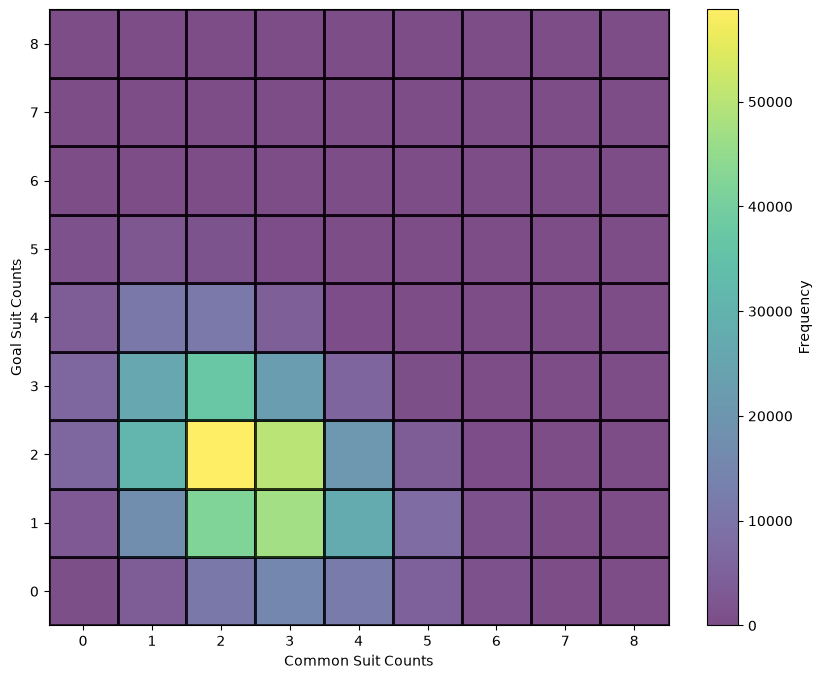

In [12]:
bins = np.arange(-0.5, max_ct + 1.5, 1)
fig, ax = plt.subplots(figsize=(10, 8))
counts, xedges, yedges, im = ax.hist2d(raw_special_cts[:, 0], raw_special_cts[:, 1], bins=[bins, bins], 
               cmap="viridis", edgecolor="black", alpha=0.7, label=f"Common/Goal Counts, {nsamples} Samples")
fig.colorbar(im, ax=ax, label="Frequency")
ax.set_xlabel("Common Suit Counts")
ax.set_ylabel("Goal Suit Counts")